In [14]:
""""Predict the price of the Uber ride from a given pickup point to the agreed drop-off location.
Perform following tasks:
1. Pre-process the dataset.
2. Identify outliers.
3. Check the correlation.
4. Implement linear regression and random forest regression models.
5. Evaluate the models and compare their respective scores like R2, RMSE, etc.
Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset"""

'"Predict the price of the Uber ride from a given pickup point to the agreed drop-off location.\nPerform following tasks:\n1. Pre-process the dataset.\n2. Identify outliers.\n3. Check the correlation.\n4. Implement linear regression and random forest regression models.\n5. Evaluate the models and compare their respective scores like R2, RMSE, etc.\nDataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset'

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [16]:
data = pd.read_csv("uber.csv")

print(data.head())
print("\nDataset Shape:", data.shape)
print("\nDataset Information:")
data.info()

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [17]:
data = data.dropna()
data = data.drop_duplicates()

data = data.drop(columns=["Unnamed: 0", "key"], errors="ignore")

data["pickup_datetime"] = pd.to_datetime(
    data["pickup_datetime"], errors="coerce"
)

data = data.dropna()

print("After Preprocessing:", data.shape)

After Preprocessing: (199999, 7)


In [18]:
data = data[
    (data["fare_amount"] > 0) &
    (data["fare_amount"] <= 100) &
    (data["passenger_count"] > 0) &
    (data["passenger_count"] <= 6) &
    (data["pickup_longitude"].between(-75, -72)) &
    (data["dropoff_longitude"].between(-75, -72)) &
    (data["pickup_latitude"].between(40, 42)) &
    (data["dropoff_latitude"].between(40, 42))
]

print("After Removing Outliers:", data.shape)

After Removing Outliers: (195022, 7)


In [19]:
def calculate_distance(lat1, lon1, lat2, lon2):

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2)**2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2)**2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))


data["distance"] = calculate_distance(
    data["pickup_latitude"],
    data["pickup_longitude"],
    data["dropoff_latitude"],
    data["dropoff_longitude"]
)

data = data[data["distance"] > 0]

print(data[["distance", "fare_amount"]].head())

   distance  fare_amount
0  1.683323          7.5
1  2.457590          7.7
2  5.036377         12.9
3  1.661683          5.3
4  4.475450         16.0


In [20]:
data["hour"] = data["pickup_datetime"].dt.hour
data["day"] = data["pickup_datetime"].dt.day
data["month"] = data["pickup_datetime"].dt.month

print(data.head())

   fare_amount           pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1          7.7 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2         12.9 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3          5.3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4         16.0 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  distance  hour  day  \
0         -73.999512         40.723217                1  1.683323    19    7   
1         -73.994710         40.750325                1  2.457590    20   17   
2         -73.962565         40.772647                1  5.036377    21   24   
3         -73.965316         40.803349                3  1.661683     8   26   
4         -73.973082         40.761247                5  4.475450    17   28   

   month  
0      5  
1      7  
2      8  


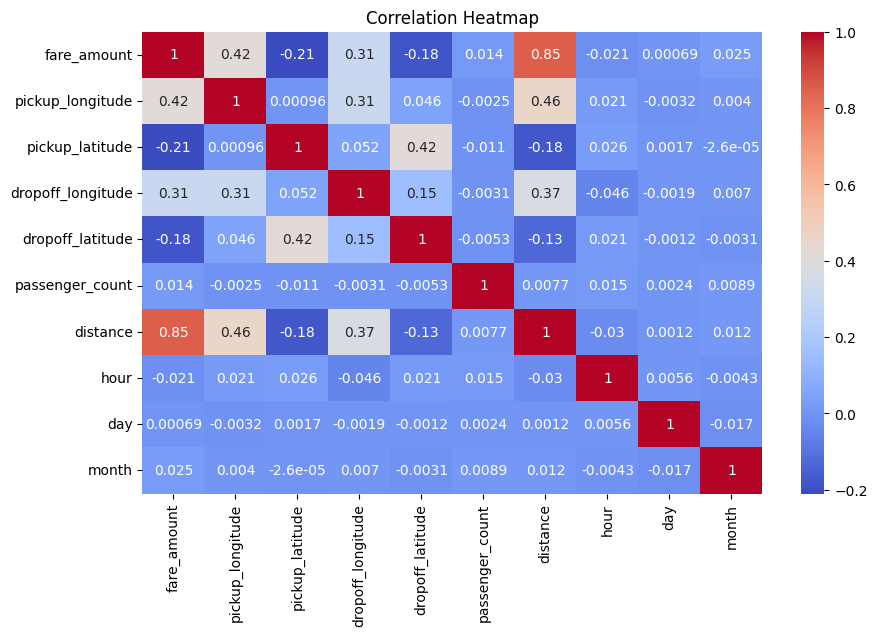

In [21]:
correlation = data.select_dtypes(include=np.number).corr()

plt.figure(figsize=(10, 6))

sns.heatmap(correlation, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

In [22]:
features = [
    "distance",
    "passenger_count",
    "hour",
    "day",
    "month"
]

X = data[features]
y = data["fare_amount"]

# Use a smaller sample to make practical execution faster
if len(X) > 30000:
    X = X.sample(30000, random_state=42)
    y = y.loc[X.index]

print(X.head())

         distance  passenger_count  hour  day  month
70225    3.955753                2    20   18      5
93460    2.687260                1    15   23     10
107798   1.673366                1     8   15      7
7882     2.168185                1     0    6     11
58285   12.307072                1    21    4      9


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (24000, 5)
Testing Data: (6000, 5)


In [24]:
lr = LinearRegression()

lr.fit(X_train, y_train)

lr_prediction = lr.predict(X_test)

print("LINEAR REGRESSION")

print("MAE:", mean_absolute_error(y_test, lr_prediction))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_prediction)))
print("R2 Score:", r2_score(y_test, lr_prediction))

LINEAR REGRESSION
MAE: 2.4690133992943144
RMSE: 4.656422946918078
R2 Score: 0.7731242514983699


In [25]:
rf = RandomForestRegressor(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_prediction = rf.predict(X_test)

print("RANDOM FOREST")

print("MAE:", mean_absolute_error(y_test, rf_prediction))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_prediction)))
print("R2 Score:", r2_score(y_test, rf_prediction))

RANDOM FOREST
MAE: 2.443303633333333
RMSE: 4.56040689221258
R2 Score: 0.7823842018920073


In [26]:
print("MODEL COMPARISON")

print("Linear Regression R2:",
      r2_score(y_test, lr_prediction))

print("Random Forest R2:",
      r2_score(y_test, rf_prediction))

MODEL COMPARISON
Linear Regression R2: 0.7731242514983699
Random Forest R2: 0.7823842018920073


In [27]:
print("MODEL COMPARISON")

print("Linear Regression R2:",
      r2_score(y_test, lr_prediction))

print("Random Forest R2:",
      r2_score(y_test, rf_prediction))

MODEL COMPARISON
Linear Regression R2: 0.7731242514983699
Random Forest R2: 0.7823842018920073
